## 03 ML Readiness

Notebook này chuẩn bị dữ liệu cho phần mô hình và kiểm định. Đầu vào là `data/processed/games_cleaned.csv`, đầu ra là `data/processed/games_features.csv`.

Nội dung gồm chọn dòng dùng được, biến đổi dữ liệu (transformation), ghép bảng (integration), giảm chiều (reduction), tạo đặc trưng (feature engineering), kiểm tra data leakage và chia train/test.

### 3.1. Đọc dữ liệu

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Thêm thư mục dự án vào đường dẫn để dùng các hàm trong src/
sys.path.insert(0, str(Path.cwd().parent))
from src.features import add_owners_mid, add_review_columns, price_group, release_period, remove_missing_owners

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("../data/processed/games_cleaned.csv", low_memory=False)
df["Release date"] = pd.to_datetime(df["Release date"])
df["Năm phát hành"] = df["Release date"].dt.year

print("Kích thước dữ liệu:", df.shape)

Kích thước dữ liệu: (125846, 22)


### 3.2. Kiểm tra lại nhóm Estimated owners = "0 - 0"

Báo cáo giữa kỳ giả định các game có Estimated owners = "0 - 0" là game chưa có người dùng. Trước khi đưa vào mô hình cần xem lại nhóm này, vì nếu xem là số 0 thật thì nhãn của mô hình sẽ sai.

In [2]:
khong_co_owner = df["Estimated owners"] == "0 - 0"
print("Số game có owners = 0 - 0:", khong_co_owner.sum())
print("Trong đó có lượt đề xuất > 0:", (df[khong_co_owner]["Recommendations"] > 0).sum())

# Các game có nhiều lượt đề xuất nhất trong nhóm này
cot_xem = ["Name", "Release date", "Price", "Recommendations", "Positive", "Peak CCU"]
display(df[khong_co_owner].sort_values("Recommendations", ascending=False)[cot_xem].head(8))

# Tỷ lệ owners = 0 - 0 theo năm phát hành
ty_le_theo_nam = khong_co_owner.groupby(df["Năm phát hành"]).mean() * 100
print("Tỷ lệ owners = 0 - 0 theo năm (%):")
print(ty_le_theo_nam.loc[2019:].round(1))

# Tỷ lệ owners = 0 - 0 ở game miễn phí và game trả phí
print("Game miễn phí:", round(khong_co_owner[df["Price"] == 0].mean() * 100, 1), "%")
print("Game trả phí:", round(khong_co_owner[df["Price"] > 0].mean() * 100, 1), "%")

Số game có owners = 0 - 0: 24572
Trong đó có lượt đề xuất > 0: 372


,Name,Release date,Price,Recommendations,Positive,Peak CCU
109703,EA SPORTS FC™ 26,2025-09-25,27.99,30317,0,0
109704,EA SPORTS FC™ 26,2025-09-25,27.99,28697,0,0
109708,EA SPORTS FC™ 26,2025-09-25,27.99,28552,0,0
100893,Assassin’s Creed Shadows,2025-03-19,34.99,27685,0,0
78830,Throne and Liberty,2024-10-01,0.00,10826,0,0
63421,Call of Duty®: Warzone™,2022-11-16,0.00,9607,0,0
71995,Command & Conquer Red Alert™ 2 and Yuri’s Reve...,2024-03-07,0.00,9147,0,0
97002,Battlefield™ REDSEC,2025-10-28,0.00,8848,0,0


Tỷ lệ owners = 0 - 0 theo năm (%):
Năm phát hành
2019     0.2
2020     0.9
2021    13.1
2022    17.8
2023    20.0
2024    22.4
2025    41.2
2026    91.0
Name: Estimated owners, dtype: float64
Game miễn phí: 62.7 %
Game trả phí: 7.9 %


Nhận xét:

- Giả định trong báo cáo giữa kỳ không đúng. Nhóm owners = "0 - 0" có 24.572 game, trong đó có EA SPORTS FC 26, Assassin's Creed Shadows và Call of Duty: Warzone. Những game này có hàng nghìn lượt đề xuất nhưng Peak CCU, Positive và owners đều bằng 0, nên đây là thiếu dữ liệu chứ không phải game không có người chơi.
- Tỷ lệ thiếu tăng từ 0,9% ở năm 2020 lên 41,2% ở năm 2025 và 91,0% ở năm 2026.
- Thiếu dữ liệu không đều giữa các nhóm: 62,7% game miễn phí bị thiếu, so với 7,9% game trả phí. Nếu xem các dòng này là số 0 thì game miễn phí sẽ bị đánh giá thấp hơn thực tế.

Vì vậy nhóm owners = "0 - 0" được xem là thiếu dữ liệu và không đưa vào mô hình.

### 3.3. Chọn các dòng dùng cho mô hình

In [3]:
so_dong_ban_dau = len(df)

# Bỏ nhóm owners = 0 - 0 vì đây là thiếu dữ liệu
data = remove_missing_owners(df)
print("Sau khi bỏ owners = 0 - 0:", len(data))

# Bỏ năm 2026 vì dữ liệu chỉ có vài tháng đầu năm
data = data[data["Năm phát hành"] <= 2025].copy()
print("Sau khi bỏ năm 2026:", len(data))

# Bỏ game thiếu Genres hoặc Categories vì không tạo được đặc trưng
data = data.dropna(subset=["Genres", "Categories"]).copy()
print("Sau khi bỏ game thiếu Genres, Categories:", len(data))

print("Tỷ lệ số dòng giữ lại:", round(len(data) / so_dong_ban_dau * 100, 1), "%")

Sau khi bỏ owners = 0 - 0: 101274
Sau khi bỏ năm 2026: 100974


Sau khi bỏ game thiếu Genres, Categories: 100025
Tỷ lệ số dòng giữ lại: 79.5 %


Nhận xét:

- Còn 100.025 game, tức 79,5% số dòng ban đầu. Phần bị bỏ chủ yếu là nhóm thiếu owners.
- Năm 2026 bị bỏ vì gần như toàn bộ game năm này thiếu dữ liệu và chỉ có các tháng đầu năm.
- Sau khi bỏ, dữ liệu còn ít game miễn phí mới, nên kết luận về game miễn phí cần chú ý điểm này (xem notebook 06 và 07).

### 3.4. Biến đổi dữ liệu (transformation)

Các cột giá, số đánh giá, thời gian chơi lệch rất mạnh nên dùng log1p, tức log(1 + x). Dùng log1p thay cho log vì dữ liệu có nhiều số 0.

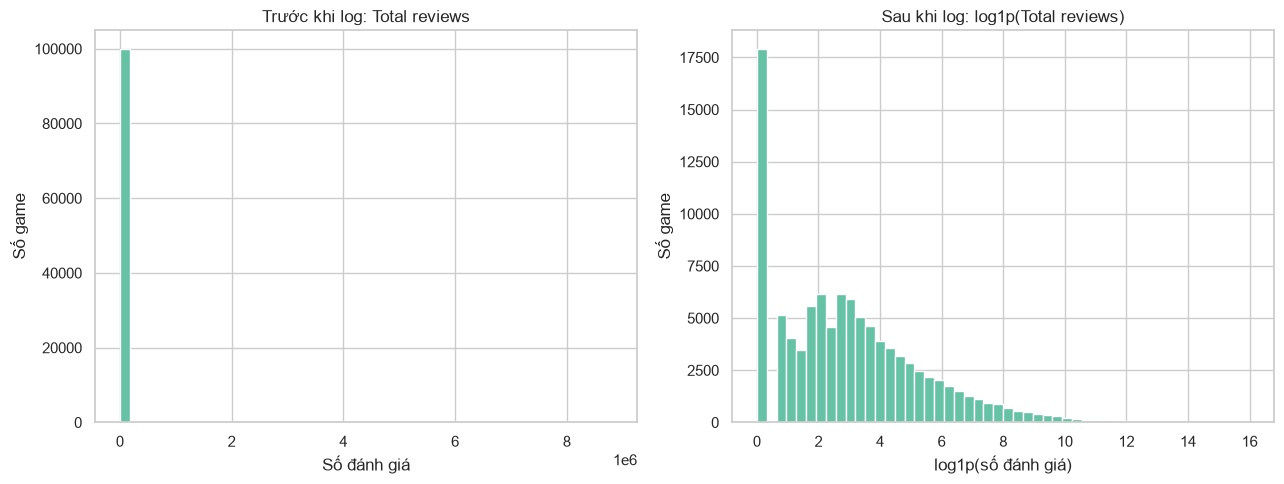

Độ lệch trước khi log: 159.47
Độ lệch sau khi log: 0.81


In [4]:
# Số người sở hữu: lấy điểm giữa của khoảng
data = add_owners_mid(data)

# Tổng đánh giá và tỷ lệ đánh giá tích cực (chỉ tính khi có từ 10 đánh giá)
data = add_review_columns(data)

# Nhóm giá và giai đoạn phát hành
data["Nhóm giá"] = data["Price"].apply(price_group)
data["Giai đoạn"] = data["Năm phát hành"].apply(release_period)

# Các cột log
data["log_price"] = np.log1p(data["Price"])
data["log_reviews"] = np.log1p(data["Total reviews"])
data["log_playtime"] = np.log1p(data["Median playtime forever"])
data["log_achievements"] = np.log1p(data["Achievements"])

# Đặc trưng đơn giản từ giá và thành tựu
data["is_free"] = (data["Price"] == 0).astype(int)
data["has_achievements"] = (data["Achievements"] > 0).astype(int)

# Nhãn cho bài toán phân loại: game có Peak CCU > 0 vào ngày ghi nhận hay không
data["has_ccu"] = (data["Peak CCU"] > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(data["Total reviews"], bins=50)
axes[0].set(title="Trước khi log: Total reviews", xlabel="Số đánh giá", ylabel="Số game")
axes[1].hist(data["log_reviews"], bins=50)
axes[1].set(title="Sau khi log: log1p(Total reviews)", xlabel="log1p(số đánh giá)", ylabel="Số game")
plt.tight_layout()
plt.show()

print("Độ lệch trước khi log:", round(data["Total reviews"].skew(), 2))
print("Độ lệch sau khi log:", round(data["log_reviews"].skew(), 2))

Nhận xét: độ lệch của Total reviews giảm từ 159,47 xuống 0,81 sau khi lấy log, nên biến này phù hợp hơn cho hồi quy tuyến tính.

### 3.5. Ghép bảng (integration)

Mỗi ô Genres và Categories chứa nhiều nhãn. Ở đây tách chúng thành một bảng riêng, mỗi dòng là một cặp (id, nhãn), đếm số game của từng nhãn, rồi tạo bảng cờ 0/1 và ghép lại vào bảng game theo khóa id.

In [5]:
# Tách Genres thành bảng dài
bang_genre = data[["id", "Genres"]].copy()
bang_genre["Genre"] = bang_genre["Genres"].str.split(",")
bang_genre = bang_genre.explode("Genre")
bang_genre["Genre"] = bang_genre["Genre"].str.strip()

# Bỏ 2 nhãn không phải thể loại nội dung, giống notebook 02
bang_genre = bang_genre[~bang_genre["Genre"].isin(["Free To Play", "Early Access"])]
print("Top thể loại:")
print(bang_genre["Genre"].value_counts().head(12))

# Tách Categories thành bảng dài
bang_cat = data[["id", "Categories"]].copy()
bang_cat["Category"] = bang_cat["Categories"].str.split(",")
bang_cat = bang_cat.explode("Category")
bang_cat["Category"] = bang_cat["Category"].str.strip()

# Chọn các thể loại và tính năng dùng làm đặc trưng
ds_genre = ["Indie", "Casual", "Action", "Adventure", "Simulation", "Strategy",
            "RPG", "Sports", "Racing", "Massively Multiplayer"]
ds_category = ["Single-player", "Multi-player", "Co-op", "Online PvP",
               "Steam Cloud", "Full controller support"]

# Tạo bảng cờ 0/1 rồi ghép vào bảng game theo id
for ten in ds_genre:
    id_co_nhan = bang_genre.loc[bang_genre["Genre"] == ten, "id"].unique()
    data["genre_" + ten] = data["id"].isin(id_co_nhan).astype(int)

for ten in ds_category:
    id_co_nhan = bang_cat.loc[bang_cat["Category"] == ten, "id"].unique()
    data["cat_" + ten] = data["id"].isin(id_co_nhan).astype(int)

cot_co = ["genre_" + ten for ten in ds_genre] + ["cat_" + ten for ten in ds_category]

# Ví dụ ghép bằng merge: thêm số thể loại của mỗi game
so_the_loai = bang_genre.groupby("id")["Genre"].nunique().rename("n_genres").reset_index()
data = data.merge(so_the_loai, on="id", how="left")
data["n_genres"] = data["n_genres"].fillna(0).astype(int)

print("Kích thước sau khi ghép:", data.shape)
print("Tỷ lệ game có mỗi cờ (%):")
print((data[cot_co].mean() * 100).round(1))

Top thể loại:
Genre
Indie                    71676
Casual                   43572
Action                   41310
Adventure                40362
Simulation               21248
Strategy                 19776
RPG                      18527
Sports                    4297
Racing                    3590
Massively Multiplayer     1908
Utilities                  433
Violent                    410
Name: count, dtype: int64


Kích thước sau khi ghép: (100025, 51)
Tỷ lệ game có mỗi cờ (%):
genre_Indie                    71.7
genre_Casual                   43.6
genre_Action                   41.3
genre_Adventure                40.4
genre_Simulation               21.2
genre_Strategy                 19.8
genre_RPG                      18.5
genre_Sports                    4.3
genre_Racing                    3.6
genre_Massively Multiplayer     1.9
cat_Single-player              95.9
cat_Multi-player               17.6
cat_Co-op                       9.7
cat_Online PvP                  7.4
cat_Steam Cloud                28.0
cat_Full controller support    23.2
dtype: float64


Nhận xét: 16 cờ thể loại và tính năng được ghép vào bảng game theo id. Single-player có ở 95,9% game nên gần như không phân biệt được các game, còn Massively Multiplayer chỉ có 1,9% nhưng vẫn giữ lại vì đây là thể loại nổi bật ở RQ1 và RQ2.

### 3.6. Giảm chiều (reduction)

Việc giảm số cột đã làm ở notebook 00. Ở đây thử thêm PCA trên 16 cờ thể loại và tính năng để xem có nén được thông tin xuống ít cột hơn không.

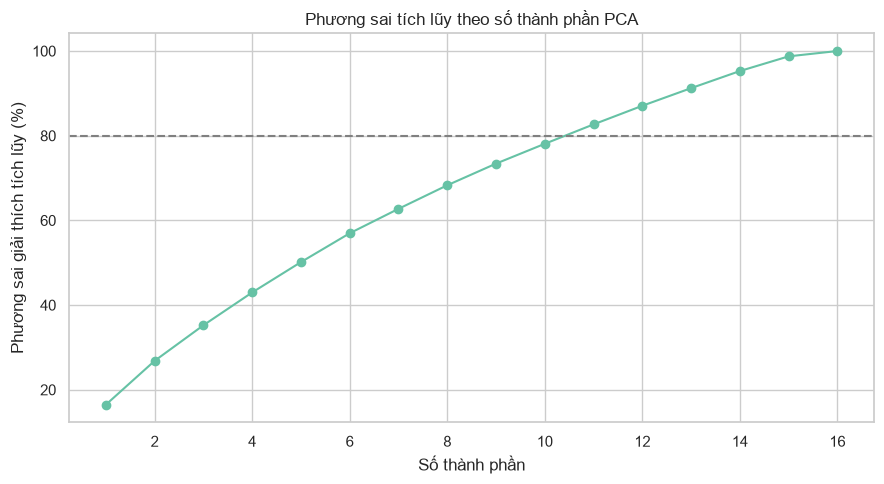

Cần 11 thành phần để giữ 80% phương sai, trên tổng 16 cột


In [6]:
X_co = StandardScaler().fit_transform(data[cot_co])
pca = PCA().fit(X_co)
tich_luy = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(tich_luy) + 1), tich_luy, marker="o")
plt.axhline(80, linestyle="--", color="gray")
plt.title("Phương sai tích lũy theo số thành phần PCA")
plt.xlabel("Số thành phần")
plt.ylabel("Phương sai giải thích tích lũy (%)")
plt.tight_layout()
plt.show()

for i in range(len(tich_luy)):
    if tich_luy[i] >= 80:
        print("Cần", i + 1, "thành phần để giữ 80% phương sai, trên tổng", len(tich_luy), "cột")
        break

Nhận xét: cần 11 thành phần để giữ 80% phương sai của 16 cột, tức PCA chỉ giảm được 5 cột. Các thành phần PCA lại khó giải thích, trong khi dự án cần biết thể loại hay tính năng nào có liên hệ. Vì vậy không dùng PCA cho mô hình, vẫn giữ nguyên 16 cờ.

### 3.7. Kiểm tra data leakage

Leakage xảy ra khi mô hình dùng thông tin chỉ có sau khi game đã phổ biến. Bảng dưới phân loại từng cột.

| Cột | Dùng làm đặc trưng? | Lý do |
|---|---|---|
| Price, is_free | Có | Nhà phát triển biết trước khi phát hành |
| Achievements | Có | Đặc điểm của game |
| Genres, Categories | Có | Do nhà phát triển khai báo |
| Năm phát hành | Có | Biết trước khi phát hành |
| Tags | Không | Do người chơi gắn, game chưa có người chơi thì chưa có Tags |
| Positive, Negative, Recommendations | Không | Là kết quả sau khi game có người chơi |
| Estimated owners, Peak CCU | Không | Là thứ cần giải thích |
| Các cột playtime | Không | Chỉ có sau khi game có người chơi |
| Discount, DLC count | Không | Là trạng thái hiện tại, thay đổi sau khi phát hành |
| Metacritic score | Không | Chỉ có sau phát hành và thiếu ở phần lớn game |

Bước kiểm tra nhanh dưới đây cho thấy vì sao không dùng Tags: tỷ lệ thiếu Tags gắn gần như trực tiếp với việc game có đánh giá hay không.

In [7]:
co_danh_gia = data["Total reviews"] > 0
print("Tỷ lệ thiếu Tags ở game chưa có đánh giá:", round(data.loc[~co_danh_gia, "Tags"].isna().mean() * 100, 1), "%")
print("Tỷ lệ thiếu Tags ở game đã có đánh giá:", round(data.loc[co_danh_gia, "Tags"].isna().mean() * 100, 1), "%")

dac_trung = ["log_price", "is_free", "has_achievements", "log_achievements",
             "Năm phát hành", "n_genres"] + cot_co
print("Số đặc trưng:", len(dac_trung))

tuong_quan = data[dac_trung + ["has_ccu"]].corr(method="spearman")["has_ccu"].drop("has_ccu")
print("Các đặc trưng tương quan mạnh nhất với has_ccu:")
print(tuong_quan.abs().sort_values(ascending=False).head(5).round(3))

Tỷ lệ thiếu Tags ở game chưa có đánh giá: 97.8 %
Tỷ lệ thiếu Tags ở game đã có đánh giá: 0.0 %
Số đặc trưng: 22


Các đặc trưng tương quan mạnh nhất với has_ccu:
cat_Steam Cloud     0.252
log_achievements    0.241
has_achievements    0.153
log_price           0.143
cat_Multi-player    0.121
Name: has_ccu, dtype: float64


Nhận xét:

- 97,8% game chưa có đánh giá bị thiếu Tags, còn game đã có đánh giá thì không thiếu. Nếu dùng Tags, mô hình sẽ gián tiếp biết game đã có người chơi hay chưa, đây là leakage.
- Không có đặc trưng nào tương quan quá mạnh với has_ccu, cao nhất là Steam Cloud với 0,252, nên không thấy dấu hiệu leakage trong 22 đặc trưng đã chọn.

### 3.8. Chia train/test

Chia 80% train và 20% test một lần ở đây rồi lưu vào cột `split`, để các notebook sau dùng chung một cách chia. Giữ nguyên tỷ lệ has_ccu ở hai tập bằng stratify. Việc chuẩn hóa dữ liệu (StandardScaler) làm trong pipeline ở notebook 04, chỉ học từ tập train để tránh leakage.

In [8]:
train_id, test_id = train_test_split(data["id"], test_size=0.2, random_state=42, stratify=data["has_ccu"])

data["split"] = "train"
data.loc[data["id"].isin(test_id), "split"] = "test"

print(data["split"].value_counts())
print("Tỷ lệ has_ccu theo tập:")
print((data.groupby("split")["has_ccu"].mean() * 100).round(2))

split
train    80020
test     20005
Name: count, dtype: int64
Tỷ lệ has_ccu theo tập:
split
test     19.4
train    19.4
Name: has_ccu, dtype: float64


### 3.9. Lưu dữ liệu

In [9]:
cot_luu = ["id", "Name", "Release date", "Năm phát hành", "Giai đoạn", "Price", "Nhóm giá",
           "Peak CCU", "Owners_mid", "Total reviews", "Positive", "Negative", "Positive ratio",
           "Metacritic score", "Recommendations", "Achievements", "Median playtime forever",
           "Median playtime two weeks", "log_reviews", "log_playtime", "has_ccu", "split"]
cot_luu = cot_luu + [c for c in dac_trung if c not in cot_luu]

data[cot_luu].to_csv("../data/processed/games_features.csv", index=False)
print("Đã lưu", data[cot_luu].shape)
print("Kiểm tra trùng id:", data["id"].duplicated().sum())
print("Số ô thiếu ở các đặc trưng:", data[dac_trung].isna().sum().sum())

Đã lưu (100025, 43)
Kiểm tra trùng id: 0
Số ô thiếu ở các đặc trưng: 0


Nhận xét: file `games_features.csv` có 100.025 game và 43 cột, không trùng id, các đặc trưng không có ô thiếu. Tỷ lệ has_ccu ở train và test đều là 19,4%.